<a href="https://colab.research.google.com/github/lucky0786-max/Statistical-Foundation-of-Data-Science/blob/main/9.%20Practical%20/%20Practical_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*PRACTICAL:9*

*vinayak pant, GF202455018*

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

In [ ]:
df = pd.read_csv("/content/iris.txt")
print(df.head())
print(df.describe())
print(df.groupby("species").size())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.057333      3.758000     1.199333
std        0.828066     0.435866      1.765298     0.762238
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000
species
setosa        50
versicolor    50
virginica     50
dtype: int64


Load dataset

describe shows statistical information

groupby count the flowers in each species


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("species", axis=1)
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

sc = StandardScaler()

X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

print("Feature scaling completed")

Feature scaling completed


Feature scaling brings all feature values to a similar scale

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=5)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(y_pred)

['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa'
 'versicolor' 'virginica' 'versicolor' 'versicolor' 'virginica' 'setosa'
 'setosa' 'setosa' 'setosa' 'versicolor' 'virginica' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'setosa' 'virginica'
 'virginica' 'virginica' 'virginica' 'virginica' 'setosa' 'setosa']


fit() trains the model.

predict() predicts the flower species.

n_neighbors=5 means K = 5

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy * 100, "%")

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]
Accuracy: 1.0 %


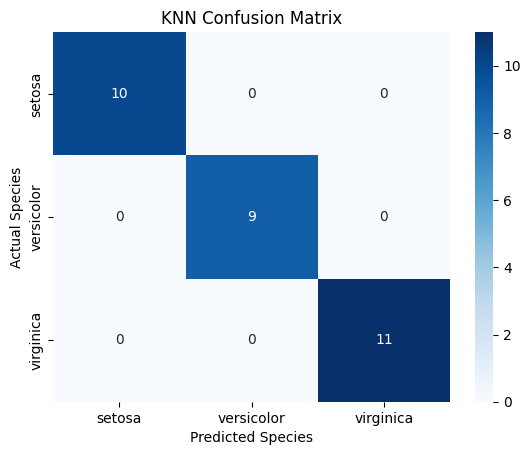

In [ ]:
sns.heatmap(
    cm,
    annot=True,
    cmap="Blues",
    fmt="d",
    xticklabels=sorted(y_test.unique()),
    yticklabels=sorted(y_test.unique())
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("KNN Confusion Matrix")
plt.show()

The confusion matrix shows correct and incorrect predictions. Accuracy shows the percentage of correct predictions

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



This report shows precision, recall, F1-score, and support for each species.

In [ ]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

error = []

for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    e = np.mean(pred != y_test)
    error.append(e)

    print("K =", k, "Error =", e)


K = 1 Error = 0.0
K = 2 Error = 0.0
K = 3 Error = 0.0
K = 4 Error = 0.0
K = 5 Error = 0.0
K = 6 Error = 0.0
K = 7 Error = 0.0
K = 8 Error = 0.0
K = 9 Error = 0.0
K = 10 Error = 0.0


This code calculates the error rate for K values from 1 to 10

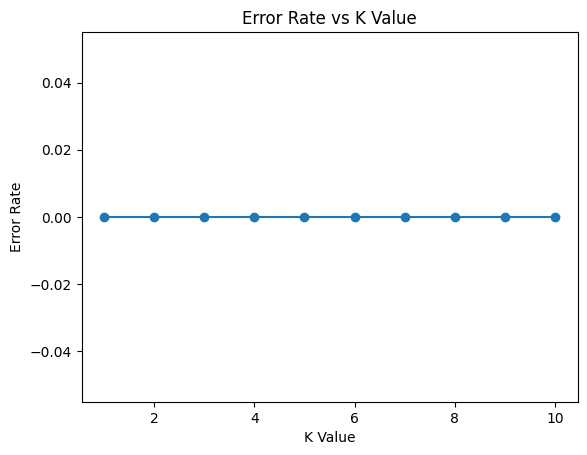

In [ ]:
import matplotlib.pyplot as plt

plt.plot(range(1, 11), error, marker="o")

plt.xlabel("K Value")
plt.ylabel("Error Rate")
plt.title("Error Rate vs K Value")

plt.show()

The graph shows how the error rate changes for different K values.

In [ ]:
best_k = error.index(min(error)) + 1

print("Best K Value:", best_k)
print("Minimum Error:", min(error))
best_model = KNeighborsClassifier(n_neighbors = best_k)
best_model.fit(X_train, y_train)
best_predictions = best_model.predict(X_test)
best_accuracy = accuracy_score(y_test, best_predictions)
print("Best Accuracy: ", best_accuracy)

Best K Value: 1
Minimum Error: 0.0
Best Accuracy:  1.0


This finds the K value with the lowest error rate on the test set.

        Actual   Predicted  Correct
0   versicolor  versicolor     True
1       setosa      setosa     True
2    virginica   virginica     True
3   versicolor  versicolor     True
4   versicolor  versicolor     True
5       setosa      setosa     True
6   versicolor  versicolor     True
7    virginica   virginica     True
8   versicolor  versicolor     True
9   versicolor  versicolor     True
10   virginica   virginica     True
11      setosa      setosa     True
12      setosa      setosa     True
13      setosa      setosa     True
14      setosa      setosa     True


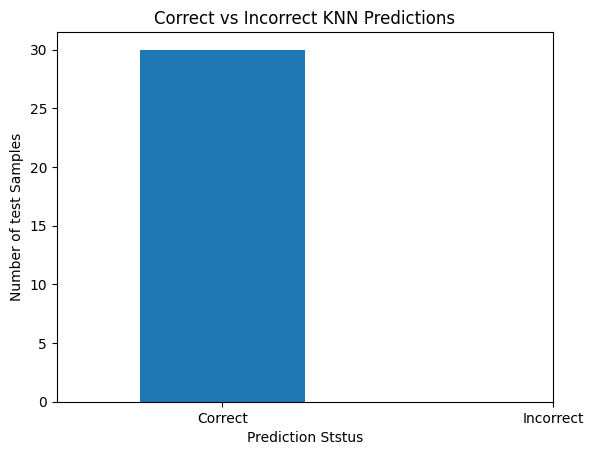

In [ ]:
results = pd.DataFrame({
    "Actual": y_test.reset_index(drop=True),
    "Predicted": pd.Series(best_predictions)
})
results["Correct"] = (
    results["Actual"] == results["Predicted"]
)
print(results.head(15))
results["Correct"].value_counts().plot(
    kind="bar"
)

plt.title("Correct vs Incorrect KNN Predictions")
plt.xlabel("Prediction Ststus")
plt.ylabel("Number of test Samples")
plt.xticks(
    [0, 1],
    ["Correct", "Incorrect"],
    rotation=0
)
plt.show()

The graph shows how correctly the model predicts the flower species. Correct predictions match the actual species, while incorrect predictions show where the model makes mistakes. This helps us understand how well the model performs